# Systemy AI – Laboratorium 1
## Python, NumPy i pierwsze metryki klasyfikacji

**Cel:** przypomnienie Pythona w kontekście pracy z wynikami modeli, samodzielna implementacja metryk klasyfikacji binarnej i pierwszy mały eksperyment z hipotezą.

**Zasady**
- Zapisz kopię notatnika na swoim Dysku: *Plik → Zapisz kopię na Dysku*, nazwa `Lab1_AI_Nazwisko.ipynb`.
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórki oznaczone `# TEST` sprawdzają rozwiązanie. Nie zmieniaj ich; jeśli zgłaszają błąd, popraw kod powyżej.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*. Notatnik musi wykonać się od góry do dołu bez błędów.



**Materiały pomocnicze**
- Python: https://www.w3schools.com/python/ oraz https://www.kaggle.com/learn/python
- NumPy: https://numpy.org/doc/stable/user/quickstart.html
- Metryki w scikit-learn: https://scikit-learn.org/stable/modules/model_evaluation.html

---
## Część A. Rozgrzewka

### Zadanie A1. Pierwsze komórki
1. Wypisz instrukcją `print` tekst `Hello, Artificial Intelligence!`.

In [1]:
# Twoje rozwiązanie
print("Hello, Artificial Intelligence!")

Hello, Artificial Intelligence!


*Twoja odpowiedź: Hello, World! :D*

### Zadanie A2. Zmienne i typy
Zadeklaruj zmienne `model`, `version`, `accuracy`, `deployed` o wartościach `"NeuralNet"`, `2`, `0.94`, `True`.

1. Wypisz typ każdej zmiennej (`type()`).
2. Zbuduj i wypisz zdanie `Model NeuralNet (v2) osiąga dokładność 0.94.` na dwa sposoby: przez konkatenację (`+`, zmienna `s1`) oraz jako f-string (zmienna `s2`).


In [2]:
# Twoje rozwiązanie
# Zmienne
model = "NeuralNet"
version = 2
accuracy = 0.94
deployed = True

# 1. Wypisz typ każdej zmiennej (type())
print("NeuralNet -", type(model))
print("2 -", type(version))
print("0.94 -", type(accuracy))
print("True -", type(deployed))
print("\n")

# 2. Zbuduj i wypisz zdanie Model NeuralNet (v2) osiąga dokładność 0.94.
s1 = "Model " + model + " (v" + str(version) + ") osiąga dokładność " + str(accuracy) + "."
s2 = f"Model {model} (v{version}) osiąga dokładność {accuracy}."
print(s1)
print(s2)

NeuralNet - <class 'str'>
2 - <class 'int'>
0.94 - <class 'float'>
True - <class 'bool'>


Model NeuralNet (v2) osiąga dokładność 0.94.
Model NeuralNet (v2) osiąga dokładność 0.94.


In [3]:
# TEST
assert s1 == s2 == "Model NeuralNet (v2) osiąga dokładność 0.94."
print("A2 OK")

A2 OK


### Zadanie A3. Średnia i odchylenie standardowe
Dla listy `acc = [0.78, 0.86, 0.92, 0.81]` oblicz **bez bibliotek**:
- średnią `mean_acc`,
- odchylenie standardowe populacji `std_acc` (z dzieleniem przez $n$):

$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

W komórce tekstowej zinterpretuj wynik: co mówi odchylenie o tych czterech modelach? Jak zmieni się wartość, jeśli podzielisz przez $n-1$, i kiedy stosuje się ten wariant?

In [4]:
# Twoje rozwiązanie
acc = [0.78, 0.86, 0.92, 0.81]
mean_acc = sum(acc) / len(acc)
std_acc = (sum((x - mean_acc) ** 2 for x in acc) / len(acc)) ** 0.5

print("Mean:", mean_acc)
print("STD:", std_acc)

Mean: 0.8425
STD: 0.05309190145398825


In [5]:
# TEST
assert abs(mean_acc - 0.8425) < 1e-9
assert abs(std_acc - 0.05309) < 1e-4, "Sprawdź, czy dzielisz przez n, a nie n-1"
print("A3 OK")

A3 OK


*Twoja odpowiedź:*
1. Odchylenie standartowe mówi nam o rozbieżności wyników dokładności w badanych modelach wokół ich średniej, która jest równa około 84.25%. Wartość odchylenia standartowego w tym przypadku jest niska (5.3%), co świadczy o niskiej rozbieżności i większej stabilności modeli - różnica pomiędzy najsłabszym a najlepszym modelem nie jest drastyczna (0.78 - 0.92).

2. Jeśli podzielić przez $n-1$ (zamiast $n$), da to wyższą wartość odchylenia standartowego. Dla naszych danych byłoby to:
   $$\sigma_{n-1} = \sqrt{\frac{1}{3} \sum_{i=1}^{n}(x_i-\bar{x})^2} \approx 0.0613\ (6.13\%)$$

Ten wariant stosuje się, gdy dane, na których dysponujemy stanowią jedynie **próbę losową** z większej populacji, a naszym celem jest oszacowanie odchylenia standardowego tej całej populacji. Użycie $n-1$ koryguje systematyczne zaniżanie wariancji. Wariant dzielenia przez $n$ stosujemy, gdy analizujemy dokładnie to co mamy - w tym przypadku, konkretne te 4 modele.

### Zadanie A4. Tekst i słownik częstości
Dla tekstu

`text = "AI systems learn from data. AI systems make predictions from data"`

1. Usuń interpunkcję, zamień litery na małe i podziel tekst na słowa.
2. Zbuduj słownik `counts` w postaci `{słowo: liczba_wystąpień}`.
3. Zapisz w liście `most_common` **wszystkie** słowa o największej liczbie wystąpień (uwaga na remisy) i wypisz ją.

In [6]:
# Twoje rozwiązanie
text = "AI systems learn from data. AI systems make predictions from data"

# 1.
newText = text.lower().replace(".", "").split()

# 2.
counts = {}
for word in newText:
    if word in counts:
        counts[word] += 1
    else:
        counts[word] = 1

 # 3.
most_common = [word for word, count in counts.items() if count == max(counts.values())]
print(counts)
print(most_common)

{'ai': 2, 'systems': 2, 'learn': 1, 'from': 2, 'data': 2, 'make': 1, 'predictions': 1}
['ai', 'systems', 'from', 'data']


In [7]:
# TEST
assert counts["data"] == 2 and counts["learn"] == 1
assert sorted(most_common) == ["ai", "data", "from", "systems"]
print("A4 OK")

A4 OK


### Zadanie A5. Funkcja z walidacją
Napisz funkcję `performance_label(score)`, która zamienia wynik modelu `score` ∈ [0, 1] na etykietę:

| Warunek | Etykieta |
|---|---|
| `score < 0.75` | `"weak"` |
| `0.75 ≤ score ≤ 0.90` | `"average"` |
| `score > 0.90` | `"strong"` |

Wymagania:
- progi 0.75 i 0.90 należą do `"average"`; funkcja nie zaokrągla wejścia,
- dla wartości nieliczbowej (np. `"0.8"`, `None`) funkcja zgłasza `TypeError`,
- dla liczby spoza [0, 1] funkcja zgłasza `ValueError`.

Następnie dla listy `scores = [0.72, 0.81, 0.93, 0.88]` wypisz każdy wynik z etykietą i policz średnią `mean_ok` tylko z wyników, które **nie** są `"weak"`.

In [8]:
# Twoje rozwiązanie
def performance_label(score):

  # TypeError (MA BYĆ PRZED PRZYPISANIEM ETYKIET!)
  if not isinstance(score, (int, float)):
    raise TypeError("Wynik powinien być liczbą.")

  # ValueError (MA BYĆ PRZED PRZYPISANIEM ETYKIET!)
  if not (0 <= score <= 1):
    raise ValueError("Wynik powinien być w przedziale [0,1].")

  # Przypisanie etykiet
  if score < 0.75:
    return "weak"
  elif 0.75 <= score <= 0.90:
    return "average"
  elif score > 0.90:
    return "strong"

scores = [0.72, 0.81, 0.93, 0.88]

# Wypisanie wyników z etykietami
print("Etykiety dla poszczególnych wyników:")
etykiety = []
for score in scores:
  etykieta = performance_label(score)
  etykiety.append(etykieta)
  print(f"Wynik: {score}, Etykieta: {etykieta}")

# Odrzucenie wyników z etykietą "weak"
wyniki_bez_weak = [score for score, etykieta in zip(scores, etykiety) if etykieta != "weak"]

# Średnia z wyników bez etykiety "weak"
mean_ok = sum(wyniki_bez_weak) / len(wyniki_bez_weak)
print(f"\nŚrednia z wyników bez etykiety 'weak': {mean_ok}")

Etykiety dla poszczególnych wyników:
Wynik: 0.72, Etykieta: weak
Wynik: 0.81, Etykieta: average
Wynik: 0.93, Etykieta: strong
Wynik: 0.88, Etykieta: average

Średnia z wyników bez etykiety 'weak': 0.8733333333333334


In [9]:
# TEST
assert [performance_label(s) for s in (0.74, 0.75, 0.90, 0.95)] == ["weak", "average", "average", "strong"]
assert performance_label(0) == "weak" and performance_label(1) == "strong"

for bad, exc in [(1.2, ValueError), (-0.1, ValueError), ("0.8", TypeError), (None, TypeError)]:
    try:
        performance_label(bad)
    except exc:
        pass
    else:
        raise AssertionError(f"Dla {bad!r} oczekiwano wyjątku {exc.__name__}")

assert abs(mean_ok - 0.87333) < 1e-4
print("A5 OK")

A5 OK


---
## Część B. Struktury danych i wyniki modeli

### Zadanie B1. Słownik wyników i ranking
1. Utwórz słownik `results`: `"SVM"` → 0.81, `"DecisionTree"` → 0.74, `"NeuralNet"` → 0.92.
2. Dodaj do niego `"Transformer"` → 0.95.
3. Oblicz średnią dokładność `mean_results` i utwórz listę `above_mean` z nazwami modeli o dokładności powyżej średniej.
4. Napisz funkcję `print_ranking(results)`, która drukuje ranking malejąco w formacie

```
1. Transformer – 0.95
2. NeuralNet – 0.92
...
Najlepszy model: Transformer – rekomendowany do wdrożenia
```

i **zwraca** nazwę najlepszego modelu. Funkcja nie może modyfikować przekazanego słownika.

In [10]:
# Twoje rozwiązanie
# 1.
results = {"SVM": 0.81, "DecisionTree": 0.74, "NeuralNet": 0.92}

# 2.
results["Transformer"] = 0.95

# 3.
mean_results = sum(results.values()) / len(results)
above_mean = [model for model, score in results.items() if score > mean_results]

print(f"Średnia dokładność: {mean_results}")
print(f"Modele powyżej średniej: {above_mean}")
print("\n")

# 4.
def print_ranking(results):
    sorted_results = sorted(results.items(), key=lambda x: x[1], reverse=True)
    for i, (model, score) in enumerate(sorted_results, start=1):
        print(f"{i}. {model} – {score}")
        if i == 1:
          bestmodel = model
    print(f"Najlepszy model: {bestmodel} – rekomendowany do wdrożenia")

    return sorted_results[0][0]

print_ranking(results)

Średnia dokładność: 0.855
Modele powyżej średniej: ['NeuralNet', 'Transformer']


1. Transformer – 0.95
2. NeuralNet – 0.92
3. SVM – 0.81
4. DecisionTree – 0.74
Najlepszy model: Transformer – rekomendowany do wdrożenia


'Transformer'

In [11]:
# TEST
assert abs(mean_results - 0.855) < 1e-9
assert sorted(above_mean) == ["NeuralNet", "Transformer"]
assert print_ranking({"A": 0.5, "B": 0.7}) == "B"
assert list(results) == ["SVM", "DecisionTree", "NeuralNet", "Transformer"], "Funkcja zmieniła słownik"
print("B1 OK")

1. B – 0.7
2. A – 0.5
Najlepszy model: B – rekomendowany do wdrożenia
B1 OK


### Zadanie B2. Filtrowanie błędnych wyników
Dane z eksperymentów bywają zanieczyszczone. Dla listy

`raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]`

napisz funkcję `clean_scores(raw)`, która zwraca parę `(valid, n_invalid)`:
- `valid` – lista poprawnych wyników (liczby z zakresu [0, 1]),
- `n_invalid` – liczba odrzuconych wartości.

Wypisz komunikat dokładnie w formacie:

`Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84`

*Dla dociekliwych:* co Twoja funkcja zrobi z wartościami `"0.9"` i `True`? Czy tak powinno być?

In [12]:
# Twoje rozwiązanie
raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]

def clean_scores(raw):
    valid = [x for x in raw if isinstance(x, (int, float)) and 0 <= x <= 1]
    # ^isinstance(x, (int, float)) sprawdza czy wartość/element x z listy w ogóle jest liczbą (int bądź float)
    # jeśli nie jest, to funkcja odrzuca element (nie zapisuje do listy valid)
    # w przypadku "0.9" - String, None czy True - funkcja odrzuci to wszystko

    n_invalid = len(raw) - len(valid)
    mean_valid = sum(valid) / len(valid) if valid else 0
    print(f"Poprawne: {len(valid)} - {valid} | Błędne: {n_invalid} | Średnia (poprawnych): {mean_valid}")
    return valid, n_invalid

print(clean_scores(raw))

Poprawne: 3 - [0.83, 0.92, 0.78] | Błędne: 3 | Średnia (poprawnych): 0.8433333333333334
([0.83, 0.92, 0.78], 3)


In [13]:
# TEST
assert clean_scores([0.83, 0.92, 1.05, -0.12, 0.78, None]) == ([0.83, 0.92, 0.78], 3)
assert clean_scores([0, 1, "0.9"]) == ([0, 1], 1)
print("B2 OK")

Poprawne: 3 - [0.83, 0.92, 0.78] | Błędne: 3 | Średnia (poprawnych): 0.8433333333333334
Poprawne: 2 - [0, 1] | Błędne: 1 | Średnia (poprawnych): 0.5
B2 OK


### Zadanie B3. Struktura zagnieżdżona
Dla struktury `model_info` (komórka niżej) napisz funkcję `summarize_model(info)`, która:
1. wypisuje nazwę modelu,
2. oblicza i wypisuje średnią ze **wszystkich** metryk w `info["metrics"]` (nie zakładaj, że są dokładnie trzy),
3. wypisuje `Model gotowy do wdrożenia`, jeśli średnia ≥ 0.9, w przeciwnym razie `Model wymaga poprawy`,
4. zapisuje średnią pod kluczem `info["mean_score"]` i zwraca cały słownik.

Wywołaj funkcję: `model_info = summarize_model(model_info)`.

In [14]:
model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

In [15]:
# Twoje rozwiązanie
def summarize_model(info):

    # 1.
    print(f"Nazwa modelu: {info['name']}")

    # 2.
    mean_score = sum(info["metrics"].values()) / len(info["metrics"])
    print(f"Średnia metryk: {mean_score}") # dla sprawdzenia

    # 3.
    if mean_score >= 0.9:
        print("Model gotowy do wdrożenia")
    else:
        print("Model wymaga poprawy")

    # 4.
    info["mean_score"] = mean_score
    return info

model_info = summarize_model(model_info)

Nazwa modelu: NeuralNet
Średnia metryk: 0.88
Model wymaga poprawy


In [16]:
# TEST
assert abs(model_info["mean_score"] - 0.88) < 1e-9
assert abs(summarize_model({"name": "X", "metrics": {"accuracy": 0.95, "f1": 0.93}})["mean_score"] - 0.94) < 1e-9
print("B3 OK")

Nazwa modelu: X
Średnia metryk: 0.94
Model gotowy do wdrożenia
B3 OK


---
## Część C. Metryki klasyfikacji binarnej

Przypomnienie (klasa pozytywna = 1):

| | predykcja 1 | predykcja 0 |
|---|---|---|
| **prawda 1** | TP | FN |
| **prawda 0** | FP | TN |

$$\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

In [17]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

### Zadanie C1. Ręcznie, w czystym Pythonie
Używając pętli (bez bibliotek) policz i zapisz w zmiennych `TP`, `FP`, `FN`, `TN`, a następnie `precision`, `recall` i `f1`. Wypisz raport:

`TP=.. FP=.. FN=.. TN=.. / precision=.. recall=.. F1=..`

In [18]:
# Twoje rozwiązanie
# Zmienne macierzy pomyłek
TP = 0
FP = 0
FN = 0
TN = 0

# Obliczanie powyższych zmiennych za pomocą pętli
for true, pred in zip(y_true, y_pred):
  if true == 1 and pred == 1:
    TP += 1
  elif true == 0 and pred == 1:
    FP += 1
  elif true == 1 and pred == 0:
    FN += 1
  elif true == 0 and pred == 0:
    TN += 1

# Obliczanie miar jakości (precision, recall i f1)
precision = TP/(TP+FP) if (TP+FP) > 0 else 0.0 # <- zabezpieczenie przed dzieleniem przez zero
recall = TP/(TP+FN) if (TP+FN) > 0 else 0.0
f1 = 2*precision*recall/(precision+recall) if (precision+recall) > 0 else 0.0

# Wypisanie raportu
print(f"TP={TP} FP={FP} FN={FN} TN={TN} / precision={precision} recall={recall} F1={f1:.4f}") # <- .4f po to, aby zaokrąglić do 4go miejsca po przecinku

TP=3 FP=1 FN=2 TN=4 / precision=0.75 recall=0.6 F1=0.6667


In [19]:
# TEST
assert (TP, FP, FN, TN) == (3, 1, 2, 4)
assert abs(precision - 0.75) < 1e-9 and abs(recall - 0.6) < 1e-9 and abs(f1 - 2 / 3) < 1e-9
print("C1 OK")

C1 OK


### Zadanie C2. To samo w NumPy
Napisz funkcję `binary_metrics(y_true, y_pred)`, która **bez pętli** (maski logiczne i `sum`) zwraca słownik z kluczami

`"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`.

Jeśli mianownik którejś metryki jest równy 0 (np. model ani razu nie przewidział klasy 1), przyjmij dla niej wartość `0.0`. Funkcja ma działać zarówno dla list, jak i tablic NumPy.

In [20]:
import numpy as np

# Twoje rozwiązanie
def binary_metrics(y_true, y_pred):

  # Konwersja na np.array, rzutowanie na int i spłaszczenie do 1D wektora - BEZ TEGO BĘDZIE ASSERTION ERROR!
  y_true = np.array(y_true).astype(int).ravel()
  y_pred = np.array(y_pred).astype(int).ravel()

  # Maski logiczne
  TP = np.sum((y_true == 1) & (y_pred == 1)).item()
  FP = np.sum((y_true == 0) & (y_pred == 1)).item()
  FN = np.sum((y_true == 1) & (y_pred == 0)).item()
  TN = np.sum((y_true == 0) & (y_pred == 0)).item()

  # Obliczanie miar jakości (precision, recall, f1 i accuracy)
  precision = TP/(TP+FP) if (TP+FP) > 0 else 0.0
  recall = TP/(TP+FN) if (TP+FN) > 0 else 0.0
  f1 = 2*precision*recall/(precision + recall) if (precision+recall) > 0 else 0.0
  accuracy = (TP+TN)/(TP+TN+FP+FN) if (TP+TN+FP+FN) > 0 else 0.0

  # Zwrot słownika
  return {"TP": TP, "FP": FP, "FN": FN, "TN": TN, "accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

In [21]:
# TEST
m = binary_metrics(y_true, y_pred)
assert (m["TP"], m["FP"], m["FN"], m["TN"]) == (3, 1, 2, 4)
assert abs(m["accuracy"] - 0.7) < 1e-9 and abs(m["f1"] - 2 / 3) < 1e-9

m0 = binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])   # model nigdy nie przewiduje 1
assert m0["precision"] == 0.0 and m0["recall"] == 0.0 and m0["f1"] == 0.0
print("C2 OK")

C2 OK


### Zadanie C3. Porównanie ze scikit-learn
Policz te same wielkości funkcjami `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` z modułu `sklearn.metrics` i sprawdź (`np.isclose`), że zgadzają się z wynikiem `binary_metrics`.

W komentarzu zapisz, w jakim układzie `confusion_matrix` zwraca TP, FP, FN, TN. Sprawdź to w dokumentacji, nie zgaduj.

In [22]:
# Twoje rozwiązanie
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Pobranie wyników z funkcji binary_metrics
m = binary_metrics(y_true, y_pred)

# Obliczanie za pomocą sklearn.metrics
tn_sk, fp_sk, fn_sk, tp_sk = confusion_matrix(y_true, y_pred).ravel()
accuracy_sk = accuracy_score(y_true, y_pred)
precision_sk = precision_score(y_true, y_pred, zero_division=0.0)
recall_sk = recall_score(y_true, y_pred, zero_division=0.0)
f1_sk = f1_score(y_true, y_pred, zero_division=0.0)

# Sprawdzenie za pomocą np.isclose(), czy wyniki się zgadzają
assert np.isclose(m["TP"], tp_sk)
assert np.isclose(m["FP"], fp_sk)
assert np.isclose(m["FN"], fn_sk)
assert np.isclose(m["TN"], tn_sk)

assert np.isclose(m["accuracy"], accuracy_sk)
assert np.isclose(m["precision"], precision_sk)
assert np.isclose(m["recall"], recall_sk)
assert np.isclose(m["f1"], f1_sk)

print("Wszystkie wyniki z sklearn zgadzają się z binary_metrics!")

Wszystkie wyniki z sklearn zgadzają się z binary_metrics!


## Poniżej jest wykres, pokazujący w jakim układzie `confusion_matrix` zwraca TP, FP, FN, TN.

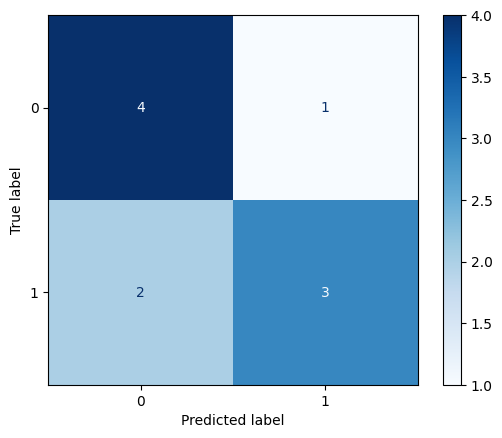

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Wygenerowanie i pokazanie wykresu
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Blues)
plt.show()

Z powyższego wykresu widać, że funkcja confusion_matrix(y_true, y_pred) domyślnie zwraca macierz w układzie:

[[ TN,  FP ],

 [ FN,  TP ]]

Gdzie:
- Wiersze odpowiadają wartościom rzeczywistym (y_true): wiersz 0 to klasa negatywna (0), wiersz 1 to klasa pozytywna (1).
- Kolumny odpowiadają wartościom przewidzianym (y_pred): kolumna 0 to klasa negatywna (0), kolumna 1 to klasa pozytywna (1).

---
## Część D. Mini-eksperyment: kiedy accuracy wprowadza w błąd

Rozważ dwa „modele” wykrywające rzadkie zjawisko (np. chorobę, awarię, oszustwo):

- **zawsze-zero** – niezależnie od wejścia odpowiada 0,
- **zaszumiony** – zna prawdziwą odpowiedź, ale w 10% przypadków (losowo) podaje przeciwną.

Parametr $p$ to udział klasy pozytywnej w danych.

### Zadanie D1. Hipoteza
**Zanim uruchomisz jakikolwiek kod**, zapisz przewidywania dla $p = 0.05$:
- jaką accuracy osiągnie każdy z modeli?
- który model będzie miał wyższą accuracy?
- jaką precision będzie miał model zaszumiony: bliżej 0.9, 0.5 czy 0.3?

*Twoja odpowiedź:*
- Accuracy wyniesie `0.95` dla modelu zawsze-zero, ponieważ model ten poprawnie wskaże wszystkie przypadki negatywne (klasa 0), które stanowią dokładnie `(1 - p = 0,95)` zbioru danych.
W przypadku modelu zaszumionego, accuracy wyniesie `0.9`, ponieważ model zna prawdziwą odpowiedź, ale myli się w 10% przypadków losowo (niezależnie od klasy). Zatem jego dokładność wynosi po prostu `(1 - 0,10 = 0,90)` w idealnym scenariuszu, ale musimy uwzględnić szum. W 90% przypadków odpowiada poprawnie (niezależnie czy to 0, czy 1), więc jego ogólna dokładność to zawsze `0,90`.

- Model zawsze-zero będzie miał większe accuracy, niż model zaszumiony. Jest to klasyczny paradoks w zbalansowaniu klas – przy bardzo rzadkich zjawiskach model "leniwy" (zawsze negatywny) statystycznie ma lepszy wynik ogólny.

- Model zaszumiony będzie miał precision bliżej 0.3 (~32%), ponieważ:
Powiedzmy, że mamy 1000 pacjentów:
  - Mamy 50 chorych `(p=0,05)` i 950 zdrowych
  - Z 50 chorych model wskaże poprawnie 90% -> 45 Prawdziwie Pozytywnych (TP)
  - Z 950 zdrowych model pomyli się w 10% i wskaże ich jako chorych -> 95 Fałszywie Pozytywnych (FP)
  - Wszystkich wskazań klasy pozytywnej (TP + FP) mamy: `45 + 95 = 140`
  - Precyzja (Precision) = $$\text{precision}=\frac{TP}{TP+FP}= 45 / 140 \approx \mathbf{0,321}$$

Funkcja poniżej generuje dane. Jest gotowa, przeczytaj ją i upewnij się, że rozumiesz każdą linię.

In [24]:
import numpy as np

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    """Zwraca (y_true, y_zero, y_noisy) dla udziału klasy pozytywnej p."""
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)        # 1 z prawdopodobieństwem p
    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero
    flip = rng.random(n) < error_rate               # które odpowiedzi odwrócić
    y_noisy = np.where(flip, 1 - y_true, y_true)    # model zaszumiony
    return y_true, y_zero, y_noisy

### Zadanie D2. Eksperyment
1. Dla $p = 0.05$ policz funkcją `binary_metrics` metryki obu modeli i porównaj z przewidywaniami z D1.
2. Powtórz obliczenia dla `ps = [0.5, 0.3, 0.1, 0.05, 0.01]`. Wyniki zbierz w tabeli `pandas.DataFrame` o nazwie `df` z kolumnami `p`, `model`, `accuracy`, `precision`, `recall`, `f1` (po jednym wierszu na parę: wartość $p$, model).
3. Narysuj wykres (matplotlib): oś X to $p$ w skali logarytmicznej, na osi Y accuracy obu modeli oraz precision modelu zaszumionego. Podpisz osie i dodaj legendę.

In [25]:
# Twoje rozwiązanie
import numpy as np
import pandas as pd

def binary_metrics(y_true, y_pred):
    # Macierz pomyłek
    TP = np.sum((y_true == 1) & (y_pred == 1)).item()
    FP = np.sum((y_true == 0) & (y_pred == 1)).item()
    FN = np.sum((y_true == 1) & (y_pred == 0)).item()
    TN = np.sum((y_true == 0) & (y_pred == 0)).item()

    # Metryki klasyfikacji
    accuracy = (TP + TN) / (TP + TN + FP + FN) if (TP + TN + FP + FN) > 0 else 0.0
    precision = TP/(TP+FP) if (TP+FP) > 0 else 0.0
    recall = TP/(TP+FN) if (TP+FN) > 0 else 0.0
    f1 = 2*precision*recall/(precision + recall) if (precision+recall) > 0 else 0

    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

# Ustawienie ziarna losowości dla powtarzalności wyników
np.random.seed(42)
N = 100000
ps = [0.5, 0.3, 0.1, 0.05, 0.01]
rows = []

for p in ps:
    # Generowanie rzeczywistych etykiet na podstawie prawdopodobieństwa p
    y_true = np.random.choice([0, 1], size=N, p=[1-p, p])

    # Model 1: zawsze-zero
    y_zero = np.zeros(N)

    # Model 2: zaszumiony (negacja losowych 10% odpowiedzi)
    noise_mask = np.random.rand(N) < 0.1
    y_noisy = y_true.copy()
    y_noisy[noise_mask] = 1 - y_noisy[noise_mask]

    # Obliczenie metryk za pomocą zdefiniowanej funkcji
    metrics_zero = binary_metrics(y_true, y_zero)
    metrics_noisy = binary_metrics(y_true, y_noisy)

    rows.append({'p': p, 'model': 'zawsze-zero', **metrics_zero})
    rows.append({'p': p, 'model': 'zaszumiony', **metrics_noisy})

# Utworzenie docelowej tabeli DataFrame
df = pd.DataFrame(rows)
print(df)

      p        model  accuracy  precision    recall        f1
0  0.50  zawsze-zero   0.49934   0.000000  0.000000  0.000000
1  0.50   zaszumiony   0.90004   0.901906  0.898015  0.899956
2  0.30  zawsze-zero   0.70010   0.000000  0.000000  0.000000
3  0.30   zaszumiony   0.89927   0.792957  0.898800  0.842568
4  0.10  zawsze-zero   0.90037   0.000000  0.000000  0.000000
5  0.10   zaszumiony   0.90061   0.500669  0.901736  0.643853
6  0.05  zawsze-zero   0.94902   0.000000  0.000000  0.000000
7  0.05   zaszumiony   0.90133   0.329154  0.901138  0.482183
8  0.01  zawsze-zero   0.98955   0.000000  0.000000  0.000000
9  0.01   zaszumiony   0.90046   0.086819  0.895694  0.158295


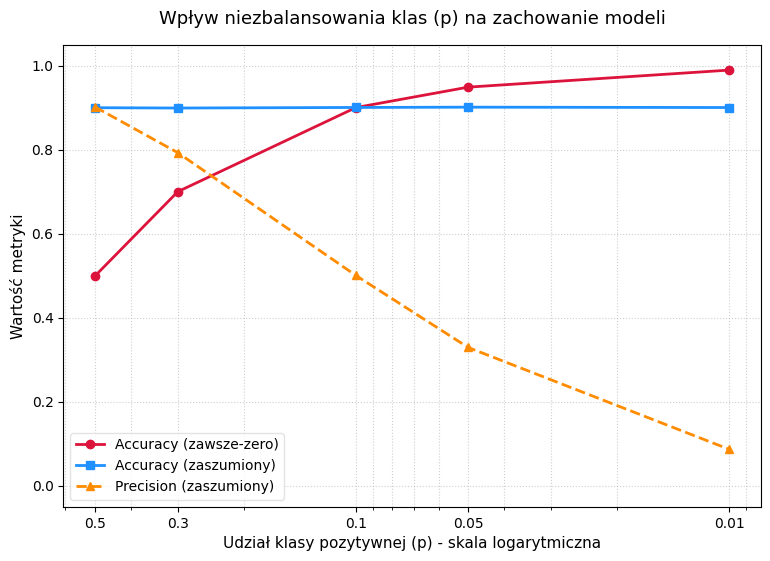

In [26]:
import matplotlib.pyplot as plt

# Twoje rozwiązanie (wykres)
df_zero = df[df['model'] == 'zawsze-zero'].sort_values('p', ascending=False)
df_noisy = df[df['model'] == 'zaszumiony'].sort_values('p', ascending=False)

plt.figure(figsize=(9, 6))

# Rysowanie linii trendu metryk
plt.plot(df_zero['p'], df_zero['accuracy'], marker='o', linewidth=2, label='Accuracy (zawsze-zero)', color='crimson')
plt.plot(df_noisy['p'], df_noisy['accuracy'], marker='s', linewidth=2, label='Accuracy (zaszumiony)', color='dodgerblue')
plt.plot(df_noisy['p'], df_noisy['precision'], marker='^', linewidth=2, linestyle='--', label='Precision (zaszumiony)', color='darkorange')

# Konfiguracja skali logarytmicznej i opisów osi
plt.xscale('log')
plt.gca().invert_xaxis()  # Opcjonalnie: odwrócenie osi X, aby p malało od 0.5 do 0.01
plt.xlabel('Udział klasy pozytywnej (p) - skala logarytmiczna', fontsize=11)
plt.ylabel('Wartość metryki', fontsize=11)
plt.title('Wpływ niezbalansowania klas (p) na zachowanie modeli', fontsize=13, pad=15)

# Dopasowanie czytelnych podpisów na osi X
plt.xticks(ps, labels=[str(p) for p in ps])
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.ylim(-0.05, 1.05)
plt.legend(frameon=True, facecolor='white', edgecolor='gainsboro')

plt.show()

In [27]:
# TEST
assert set(df.columns) >= {"p", "model", "accuracy", "precision", "recall", "f1"}
assert len(df) == 10
z = df[(df["model"] == "zawsze-zero") & (df["p"] == 0.01)].iloc[0]
assert z["accuracy"] > 0.98 and z["recall"] == 0.0
print("D2 OK")

D2 OK


### Zadanie D3. Wnioski
Odpowiedz krótko (2–3 zdania na pytanie), odwołując się do liczb z tabeli:

1. Czy Twoje przewidywania z D1 się potwierdziły? Co Cię zaskoczyło?
2. Dla $p = 0.01$: który model ma wyższą accuracy, a który jest bardziej użyteczny? Dlaczego?
3. Model zaszumiony myli się zawsze w 10% przypadków. Dlaczego mimo to jego precision spada, gdy $p$ maleje?
4. Projektujesz system wykrywający rzadką chorobę. Którą metrykę zaraportujesz jako główną? Jakie konsekwencje dla pacjentów mają błędy FP, a jakie FN?

*Twoja odpowiedź:*
1. Moje przewidywania z D1 się potwierdziły - dla `p = 0.05` accuracy i precision wyniosły:
  - Accuracy 90% dla modelu zaszumionego
  - Accuracy 95% dla modelu zawsze-zero
  - Precision 32-33% dla modelu zaszumionego

Zaskoczyło mnie raczej to, że accuracy dla modelu zaszumionego jest na stałym wysokim poziomie mimo występowania szumu, zaś skala accuracy dla modelu zawsze-zero nie była stała - co widać na wykresie.

2. Dla $p = 0.01$ model zawsze-zero ma większe accuracy - 99% w porównaniu do modelu zaszumionego, który ma 90%. Mimo to, model zawsze-zero jest bezużyteczny, ponieważ jego zdolność wykrywania klasy pozytywnej `recall` wynosi dokładnie 0. Nie wykryje żadnej awarii, oszustwa ani chorego pacjenta. Dlatego model zaszumiony jest bardziej użyteczny.

3. Gdy $p$ maleje, drastycznie rośnie liczba zdrowych/poprawnych przypadków (klasa 0), z których generowane są błędy typu Fałszywie Pozytywne (FP). W tym przypadku, dla $p = 0.01$, mamy na 1000 osób 990 zdrowych i 10 chorych. Model poprawnie wskaże ok. 9 chorych (TP), ale pomyli się przy 10% zdrowych, generując 99 fałszywych alarmów (FP). W takim razie $precision \approx 8,3$%. Ponieważ baza zdrowych ludzi jest ogromna, fałszywe alarmy całkowicie „zalewają” i maskują trafne diagnozy.

4. Zaproponuję metrykę `recall`. Metryka ta kładzie znacznie większy nacisk na wykrywanie chorych niż na unikanie fałszywych alarmów. Konsekwencje błędów dla pacjentów:
- Fałszywie Negatywny (FN) - Model mówi „zdrowy”, pacjent jest chory:
To najgroźniejszy błąd. Pacjent nie otrzymuje pomocy na czas. Choroba rozwija się bez leczenia, co bezpośrednio zagraża jego życiu lub zdrowiu.

- Fałszywie Pozytywny (FP) - Model mówi „chory”, pacjent jest zdrowy:
Pacjent przeżywa ogromny stres emocjonalny i jest kierowany na niepotrzebne, często inwazyjne lub kosztowne badania diagnostyczne drugiego stopnia (np. biopsja, rezonans). Błąd ten generuje koszty dla szpitala i obciąża psychikę pacjenta, ale ostatecznie kolejna weryfikacja lekarska wykluczy chorobę.


---
## Część E. Zadania dodatkowe (dla chętnych / do domu)

**E1. Pliki.** Zapisz listę wyników (po jednym w linii) do pliku `scores.txt`. Wczytaj plik, oblicz średnią i zapisz do `report.txt` raport w formacie `Wczytano N wyników, średnia: X` (X z dokładnością do 3 miejsc po przecinku).

**E2. Dane od użytkownika.** Pobierz funkcją `input()` wynik modelu `s` i wypisz:
- `Podano niepoprawną wartość!`, gdy tekstu nie da się zamienić na liczbę (`try`/`except`),
- `Wynik poza zakresem 0–1`, gdy `s < 0` lub `s > 1`,
- `Model wymaga poprawy`, gdy `s < 0.7`,
- `Wynik akceptowalny`, gdy `0.7 ≤ s < 0.85`,
- `Wynik doskonały` w pozostałych przypadkach.

**E3. Duplikaty.** Usuń duplikaty z listy `["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]` **z zachowaniem kolejności** pierwszych wystąpień. Dlaczego samo `list(set(...))` tego nie gwarantuje?

**E4. Uogólnienie.** Rozszerz `make_data` o parametr pozwalający ustawić osobno odsetek błędów dla przykładów pozytywnych i negatywnych. Jak zmienia się wykres z D2, gdy model myli się w 10% pozytywnych, ale tylko w 1% negatywnych?

In [28]:
# Twoje rozwiązanie
# E1. Pliki.
# 1. Przygotowanie przykładowej listy i zapis do pliku scores.txt
from random import random
scores_count = 3000

with open("scores.txt", "w", encoding="utf-8") as f:
    for score in range(scores_count):
        f.write(f"{random():.2f}\n")  # Zapis każdego wyniku w nowej linii

# 2. Wczytanie danych z pliku scores.txt
read_scores = []
with open("scores.txt", "r", encoding="utf-8") as f:
    for line in f:
        clean_line = line.strip()
        if clean_line:  # Pomijanie ewentualnych pustych linii
            read_scores.append(float(clean_line))

# 3. Obliczenia (N oraz średnia X)
n = len(read_scores)
if n > 0:
    avg = sum(read_scores) / n
else:
    avg = 0.0

# 4. Zapis raportu do pliku report.txt
report_text = f"Wczytano {n} wyników, średnia: {avg:.3f}"

with open("report.txt", "w", encoding="utf-8") as f:
    f.write(report_text)

print(report_text)
print("Zadanie E1 zakończone sukcesem. Wygenerowano report.txt.")

Wczytano 3000 wyników, średnia: 0.508
Zadanie E1 zakończone sukcesem. Wygenerowano report.txt.


In [29]:
# E2. Dane od użytkownika.
# 1. Pobranie wartości od użytkownika
user_input = input("Podaj wynik modelu (s): ")

# 2. Próba konwersji na liczbę zmiennoprzecinkową (try/except)
try:
    s = float(user_input)

    # 3. Weryfikacja zakresu i kryteriów oceny modelu
    if s < 0 or s > 1:
        print("Wynik poza zakresem 0–1")
    elif s < 0.7:
        print("Model wymaga poprawy")
    elif 0.7 <= s < 0.85:
        print("Wynik akceptowalny")
    else:
        print("Wynik doskonały")

except ValueError:
    print("Podano niepoprawną wartość!")

Podaj wynik modelu (s): 0.9
Wynik doskonały


In [30]:
# E3. Duplikaty.
# 1. Definicja listy wejściowej z duplikatami
models = ["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]

# 2. Usunięcie duplikatów z zachowaniem kolejności
# W Pythonie 3.7+ zwykłe słowniki (dict) gwarantują zachowanie kolejności dodawania kluczy.
# Metoda dict.fromkeys() tworzy słownik, w którym elementy listy stają się unikalnymi kluczami.
unique_models = list(dict.fromkeys(models))

# 3. Wypisanie wyniku
print("Lista bez duplikatów:", unique_models)

Lista bez duplikatów: ['SVM', 'NeuralNet', 'Transformer']


Samo `list(set(...))` nie gwarantuje kolejności, ponieważ `set` (zbiór) jest strukturą nieuporządkowaną. Elementy są w nim układane na podstawie funkcji mieszającej (hash), a oryginalna kolejność ich dodawania zostaje bezpowrotnie utracona.

W Pythonie 3.5 i starszych standardowe słowniki również nie pamiętają kolejności. Aby rozwiązać ten problem, można użyć poniższej pętli.

In [31]:
models_2 = ["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]
seen = set()
result_2 = []

for m in models_2:
    if m not in seen:
        seen.add(m)
        result_2.append(m)

print("Lista bez duplikatów:", result_2)

Lista bez duplikatów: ['SVM', 'NeuralNet', 'Transformer']


Powyżej mamy uniwersalne rozwiązanie dla każdej wersji językowej. Zbiór `seen` zapewnia błyskawiczne sprawdzanie duplikatów, a lista `result_2` zachowuje właściwy porządek.

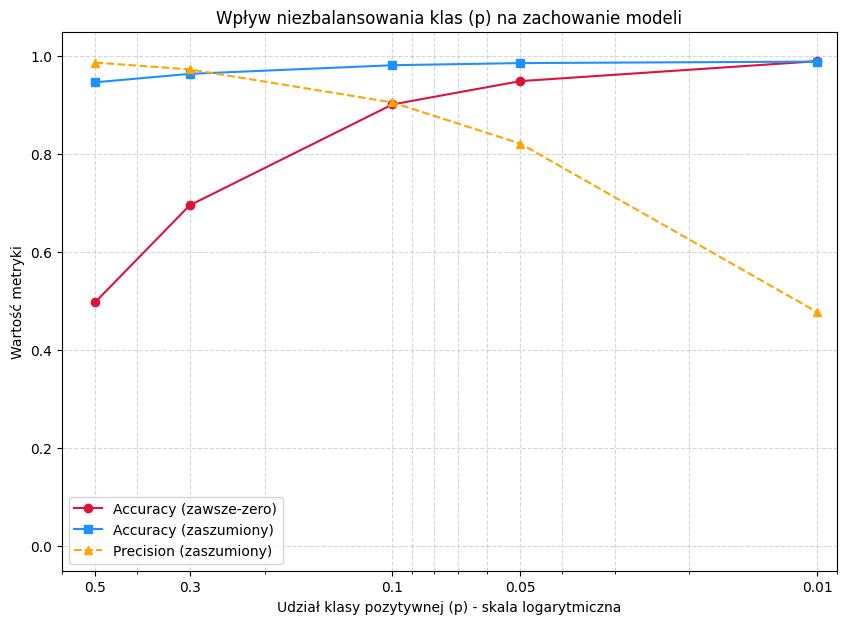

In [32]:
# E4. Uogólnienie.
import numpy as np
import matplotlib.pyplot as plt

def make_data(p, n=10_000, error_pos=0.10, error_neg=0.01, seed=42):
    """Zwraca (y_true, y_zero, y_noisy) dla udziału klasy pozytywnej p."""
    rng = np.random.default_rng(seed)

    # 1. Generowanie prawdziwych etykiet
    y_true = (rng.random(n) < p).astype(int)        # 1 z prawdopodobieństwem p
    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero

    # 2. Definiowanie masek błędów osobno dla każdej klasy
    flip_pos = (rng.random(n) < error_pos) & (y_true == 1)  # Błędy w klasie pozytywnej (FN)
    flip_neg = (rng.random(n) < error_neg) & (y_true == 0)  # Błędy w klasie negatywnej (FP)

    # Połączenie masek (odwracamy bity tam, gdzie wystąpił błąd dla danej klasy)
    flip = flip_pos | flip_neg

     # 3. Wygenerowanie predykcji zaszumionego modelu
    y_noisy = np.where(flip, 1 - y_true, y_true)    # model zaszumiony

    return y_true, y_zero, y_noisy

# Definicja punktów p (skala logarytmiczna z oryginalnego wykresu)
p_values = [0.5, 0.3, 0.1, 0.05, 0.01]

# Listy na metryki
acc_zero_list = []
acc_noisy_list = []
prec_noisy_list = []

# Wykorzystanie zwracanych zmiennych do obliczenia metryk
for p in p_values:
    y_true, y_zero, y_noisy = make_data(p, error_pos=0.10, error_neg=0.01)

    # Obliczenia dla modelu zawsze-zero
    acc_zero = np.mean(y_true == y_zero)

    # Obliczenia dla modelu zaszumionego
    acc_noisy = np.mean(y_true == y_noisy)

    # Precyzja (Precision) dla modelu zaszumionego: TP / (TP + FP)
    tp = np.sum((y_noisy == 1) & (y_true == 1))
    fp = np.sum((y_noisy == 1) & (y_true == 0))
    prec_noisy = tp / (tp + fp) if (tp + fp) > 0 else 0.0

    acc_zero_list.append(acc_zero)
    acc_noisy_list.append(acc_noisy)
    prec_noisy_list.append(prec_noisy)

# Rysowanie nowego wykresu
plt.figure(figsize=(10, 7))

# Wykresy linii
plt.plot(p_values, acc_zero_list, label='Accuracy (zawsze-zero)', color='crimson', marker='o')
plt.plot(p_values, acc_noisy_list, label='Accuracy (zaszumiony)', color='dodgerblue', marker='s')
plt.plot(p_values, prec_noisy_list, label='Precision (zaszumiony)', color='orange', linestyle='--', marker='^')

# Konfiguracja osi X (odwrócona skala logarytmiczna jak na wzorze)
plt.xscale('log')
plt.xlim(0.6, 0.009)
plt.xticks(p_values, [str(p) for p in p_values])

# Estetyka
plt.title('Wpływ niezbalansowania klas (p) na zachowanie modeli')
plt.xlabel('Udział klasy pozytywnej (p) - skala logarytmiczna')
plt.ylabel('Wartość metryki')
plt.ylim(-0.05, 1.05)
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend()
plt.show()

Wprowadzenie asymetrycznego szumu (10% błędów dla klasy pozytywnej i 1% dla klasy negatywnej) powoduje następujące zmiany na wykresie w porównaniu do zadania D2:

1. **Accuracy (zawsze-zero)**:
   * **Bez zmian** - metryka ta zależy wyłącznie od rozkładu klas w danych ($1 - p$), więc zachowuje identyczny kształt i rośnie od **0.50** (dla $p=0.5$) do **0.99** (dla $p=0.01$).

2. **Accuracy (zaszumiony)**:
   * W zadaniu D2 linia ta była płaska na stałym poziomie **0.90**.
   * Na nowym wykresie dokładność modelu zaszumionego **nie jest stała i rośnie wraz ze spadkiem $p$**. Dla $p=0.5$ wynosi **0.95**, a dla $p=0.01$ osiąga aż **0.99**. Wynika to z faktu, że wraz ze spadkiem udziału klasy pozytywnej, o ogólnej dokładności zaczyna decydować niemal bezbłędna (1% błędu) klasa negatywna.

3. **Precision (zaszumiony)**:
   * W obu przypadkach precyzja drastycznie spada wraz ze spadkiem $p$, jednak na nowym wykresie **spadek ten jest znacznie łagodniejszy**.
   * Dla skrajnego niezbalasowania ($p=0.01$) precyzja w zadaniu D2 wynosiła około **0.09** (9%). W nowym układzie, dzięki ograniczeniu błędów typu False Positive w klasie negatywnej do zaledwie 1%, precyzja dla $p=0.01$ wynosi aż około **0.47** (47%).
